# Task 3: Recognizing Handwritten Digits

In this task of the project we aim at building and training an artificial deep neural network that recognises and predicts handwritten numbers. We will build a feedforward neural-network that consists of functions to cover different aspects of building, training and testing phases. 

### What is a feedforward neural-network architecture?

Feedforward neural-network is a type of architecture design used in ANN. FNN is a specific type of artificial neural network where connections between the nodes do not form any type of cycle or in other words the information moves in one direction only: from the input layer to the hidden layers to the output layer. The structure of an FNN is acyclic, meaning you cannot start from one neuron and follow the connections to return to the same neuron.

##### Visually representation: `Input Layer` → `Hidden Layer 1` → `Output Layer`

### How we will structure the architecture of the FNN for recognising (predicting) handwritten digits from the MNIST dataset? 

#### Functions to structure our FNN: 

##### 1. Data Preparation 

`load_data():` Load the MNIST dataset.

`flatten_images():` Prepare the images for the model input by flattening them.

`split_target()`: Splitting the data into target and features

`split_train_test()` Splitting the data into training and testing

`subset_select()` Function to select an appropriate sample size for initial experimentation

##### 2. Initialization

`initialize_parameters(input_size, hidden_size, output_size):` Initialize the weights and biases.

- input_size = 784: Because the images in the MNIST dataset are 28x28 pixels and when we flatten them we get a 784 dimensional vector (28x28=784). 

- hidden_size = N: We want to optimise the number of hidden layers in order to have faster and better predictions. 

- output_size = 10: Because there are numbers from 0-9 and this makes 10 total classes for prediction. If we lower the output_size we will get a lot of wrong predictions.

##### 3. Forward Propagation: 

`relu(x):` Apply the ReLU activation function. The ReLU (Rectified Linear Unit) activation function is used to introduce non-linearity into the network. It is defined as: 

ReLU(x)=max(0,x)

We need the non-linearity in order for the neural network to learn more complex patterns in the data.

`softmax(x):` Apply the Softmax activation function. The Softmax activation function is used in the output layer of a classification network. It converts the raw output scores (logits) into probabilities that sum up to 1.

 Softmax ensures that the output values can be interpreted as probabilities.

`forward_propagation(X, W1, b1, W2, b2):` Computes the forward pass through the network, from input to output, using linear transformations and activation functions.

##### 4. Loss Calculation

`cross_entropy_loss(y_true, y_pred):` Calculate the cross-entropy loss between the true values and the predicted ones. 

##### 5. Backward Propagation 

`relu_derivative():` This function computes the derivatives of the ReLU function.

`apply_dropout(A, keep_prob):` Apply dropout to the activations during training.

`backward_propagation(X, Y, Z1, A1, Z2, A2, W1, W2):` Compute the backward pass where we optimise the weights and biases by going from the output to the input.

##### 6. Training Loop

`update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):` This function updates the weights and biases. 

`train_neural_network(X_train, Y_train, X_val, Y_val, hidden_size, learning_rate, epochs, batch_size)`: Train the network using forward and backward propagation.

`learning_rate_scheduler(epoch, initial_lr):` Adjust the learning rate as training progresses.

`hyperparameter_tuning(X_train, Y_train, X_val, Y_val):` Find optimal hyperparameters using grid search or random search.

##### 7. Evaluation 

`calculate_accuracy(y_true, y_pred):` Calculate the accuracy of the model.

`evaluate_model(X_test, y_test, W1, b1, W2, b2): `Evaluate the trained model on the test set.

### Our FNN architecture will consist of the following layers:

Input Layer (784 nodes) → Hidden Layer 1 (128 nodes) -- ReLU Activation → Output Layer (10 nodes)

***
# 1. Data Preparation

In [81]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

def load_data():
    (X_train, y_train), (X_test, y_test) = mnist.load_data()
    return X_train, y_train, X_test, y_test

def flatten_images(X_train, X_test):
    X_train = X_train.reshape(X_train.shape[0], -1)
    X_test = X_test.reshape(X_test.shape[0], -1)
    return X_train, X_test

def one_hot_encode(y, num_classes):
    return np.eye(num_classes)[y]

def split_train_test(X_train, y_train, X_test, y_test):
    X_train = X_train / 255.0
    X_test = X_test / 255.0
    return X_train, y_train, X_test, y_test

def subset_select(X_train, y_train, X_test, y_test, n):
    X_train = X_train[:n]
    y_train = y_train[:n]
    X_test = X_test[:n]
    y_test = y_test[:n]
    return X_train, y_train, X_test, y_test

def initialize_parameters(input_size, hidden_size, output_size):
    W1 = np.random.randn(hidden_size, input_size) * 0.01
    b1 = np.zeros((hidden_size, 1))
    W2 = np.random.randn(output_size, hidden_size) * 0.01
    b2 = np.zeros((output_size, 1))
    return W1, b1, W2, b2

def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x <= 0, 0, 1)

def softmax(x):
    exps = np.exp(x - np.max(x, axis=0, keepdims=True))
    return exps / np.sum(exps, axis=0, keepdims=True)

def forward_propagation(X, W1, b1, W2, b2):
    Z1 = np.dot(W1, X) + b1
    A1 = relu(Z1)
    Z2 = np.dot(W2, A1) + b2
    A2 = softmax(Z2)
    return Z1, A1, Z2, A2

def cross_entropy_loss(y_true, y_pred):
    m = y_true.shape[1]
    log_likelihood = -np.log(y_pred[y_true.argmax(axis=0), range(m)] + 1e-8)
    loss = np.sum(log_likelihood) / m
    return loss

def backward_propagation(X, Y, Z1, A1, Z2, A2, W1, W2):
    m = X.shape[1]
    dZ2 = A2 - Y
    dW2 = (1 / m) * np.dot(dZ2, A1.T)
    db2 = (1 / m) * np.sum(dZ2, axis=1, keepdims=True)
    dA1 = np.dot(W2.T, dZ2)
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = (1 / m) * np.dot(dZ1, X.T)
    db1 = (1 / m) * np.sum(dZ1, axis=1, keepdims=True)
    return dW1, db1, dW2, db2

def update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate):
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    return W1, b1, W2, b2

def train_neural_network(X_train, y_train, X_val, y_val, hidden_size, learning_rate, epochs, batch_size):
    input_size = X_train.shape[1]
    output_size = y_train.shape[1]
    W1, b1, W2, b2 = initialize_parameters(input_size, hidden_size, output_size)
    
    for epoch in range(epochs):
        permutation = np.random.permutation(X_train.shape[0])
        X_train_shuffled = X_train[permutation]
        y_train_shuffled = y_train[permutation]
        
        for i in range(0, X_train.shape[0], batch_size):
            X_batch = X_train_shuffled[i:i + batch_size].T
            Y_batch = y_train_shuffled[i:i + batch_size].T
            
            Z1, A1, Z2, A2 = forward_propagation(X_batch, W1, b1, W2, b2)
            dW1, db1, dW2, db2 = backward_propagation(X_batch, Y_batch, Z1, A1, Z2, A2, W1, W2)
            W1, b1, W2, b2 = update_parameters(W1, b1, W2, b2, dW1, db1, dW2, db2, learning_rate)
        
        if epoch % 10 == 0:
            Z1, A1, Z2, A2 = forward_propagation(X_val.T, W1, b1, W2, b2)
            val_loss = cross_entropy_loss(y_val.T, A2)
            print(f"Epoch {epoch}, Val Loss: {val_loss}")
    
    return W1, b1, W2, b2

def evaluate_model(X_test, y_test, W1, b1, W2, b2):
    _, _, _, A2 = forward_propagation(X_test.T, W1, b1, W2, b2)
    predictions = np.argmax(A2, axis=0)
    labels = np.argmax(y_test.T, axis=0)
    accuracy = np.mean(predictions == labels)
    return accuracy

In [ ]:
# Load the data
X_train, y_train, X_test, y_test = load_data()
# Flatten the images
X_train, X_test = flatten_images(X_train, X_test)
# One-hot encode the labels
y_train = one_hot_encode(y_train, 10)
y_test = one_hot_encode(y_test, 10)
# Normalize the data
X_train, y_train, X_test, y_test = split_train_test(X_train, y_train, X_test, y_test)
# Select a subset of the data for initial experimentation
X_train, y_train, X_test, y_test = subset_select(X_train, y_train, X_test, y_test, 10000)

# Train the neural network
W1, b1, W2, b2 = train_neural_network(X_train, y_train, X_test, y_test, hidden_size=124, learning_rate=0.04, epochs=150, batch_size=64)

# Evaluate the model
accuracy = evaluate_model(X_test, y_test, W1, b1, W2, b2)
print(f"Test Accuracy: {accuracy}")


In [ ]:
# 2. Data Visualization

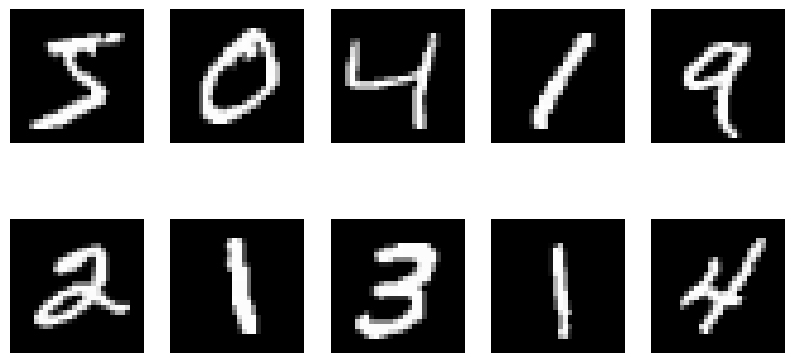

In [70]:
# Visualize the data
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()
for i in range(10):
    axes[i].imshow(X_train[i].reshape(28, 28), cmap='gray')
    axes[i].axis('off')
plt.show()

In [ ]:
# Confusion Matrix

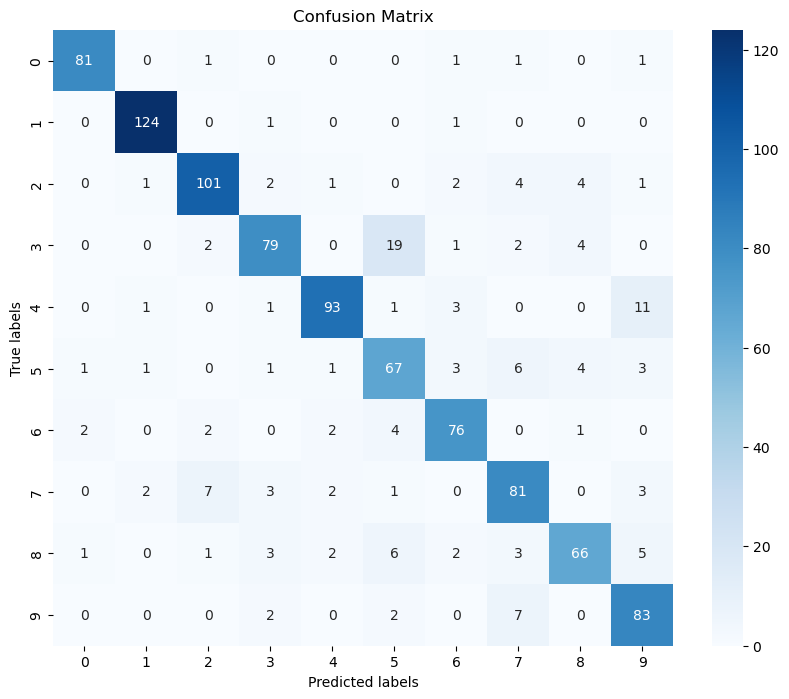

In [71]:
# Importing the required libraries
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Get the predictions
_, _, _, A2 = forward_propagation(X_test.T, W1, b1, W2, b2)
predictions = np.argmax(A2, axis=0)

# Get the true labels
labels = np.argmax(y_test.T, axis=0)

# Create the confusion matrix
cm = confusion_matrix(labels, predictions)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Train the model with the full dataset

In [72]:
# Load the data
X_train, y_train, X_test, y_test = load_data()
# Flatten the images
X_train, X_test = flatten_images(X_train, X_test)
# One-hot encode the labels
y_train = one_hot_encode(y_train, 10)
y_test = one_hot_encode(y_test, 10)
# Normalize the data
X_train, y_train, X_test, y_test = split_train_test(X_train, y_train, X_test, y_test)

# Train the neural network with the full dataset
W1, b1, W2, b2 = train_neural_network(X_train, y_train, X_test, y_test, hidden_size=124, learning_rate=0.04, epochs=150, batch_size=64)

# Evaluate the model
accuracy = evaluate_model(X_test, y_test, W1, b1, W2, b2)
print(f"Test Accuracy: {accuracy}")

Epoch 0, Val Loss: 0.3625808539928964
Epoch 10, Val Loss: 0.12399104901756468
Epoch 20, Val Loss: 0.0872260569501318
Epoch 30, Val Loss: 0.07555879205116874
Epoch 40, Val Loss: 0.070223503408906
Epoch 50, Val Loss: 0.06784118815978896
Epoch 60, Val Loss: 0.06645117914161525
Epoch 70, Val Loss: 0.06770177050594668
Epoch 80, Val Loss: 0.06757851657971031
Epoch 90, Val Loss: 0.06971607471831615
Epoch 100, Val Loss: 0.07049154581563395
Epoch 110, Val Loss: 0.07114905836265016
Epoch 120, Val Loss: 0.07214378123808306
Epoch 130, Val Loss: 0.07342478787303583
Epoch 140, Val Loss: 0.07491230465217456
Test Accuracy: 0.9799


In [ ]:
# Confusion Matrix

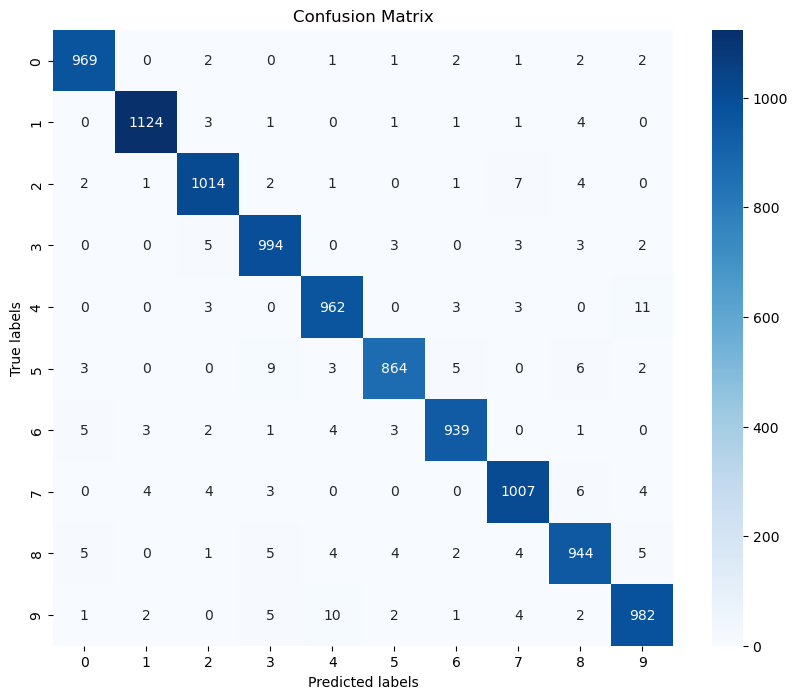

In [73]:
# Get the predictions
_, _, _, A2 = forward_propagation(X_test.T, W1, b1, W2, b2)
predictions = np.argmax(A2, axis=0)

# Get the true labels
labels = np.argmax(y_test.T, axis=0)

# Create the confusion matrix
cm = confusion_matrix(labels, predictions)

# Plot the confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
plt.xlabel('Predicted labels')
plt.ylabel('True labels')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Show images with their predicted labels

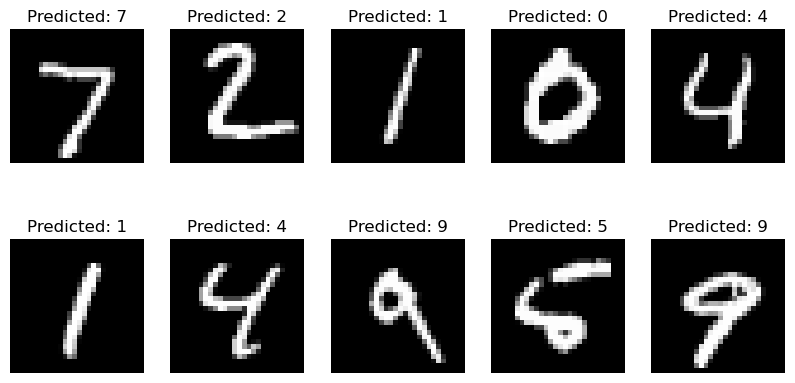

In [74]:
# Get the predictions
_, _, _, A2 = forward_propagation(X_test.T, W1, b1, W2, b2)
predictions = np.argmax(A2, axis=0)

# Visualize the data
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()

for i in range(10):
    axes[i].imshow(X_test[i].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Predicted: {predictions[i]}")
    axes[i].axis('off')
    
plt.show()

In [ ]:
# Find the misclassified images

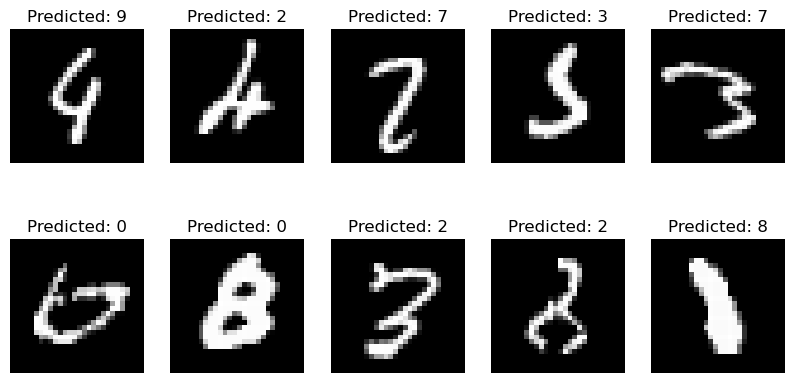

In [75]:
# Get the misclassified images
misclassified_images = X_test[predictions != labels]
misclassified_labels = predictions[predictions != labels]

# Visualize the misclassified images
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()

for i in range(10):
    axes[i].imshow(misclassified_images[i].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Predicted: {misclassified_labels[i]}")
    axes[i].axis('off')
    
plt.show()

In [ ]:
# Order the misclassified images by confidence

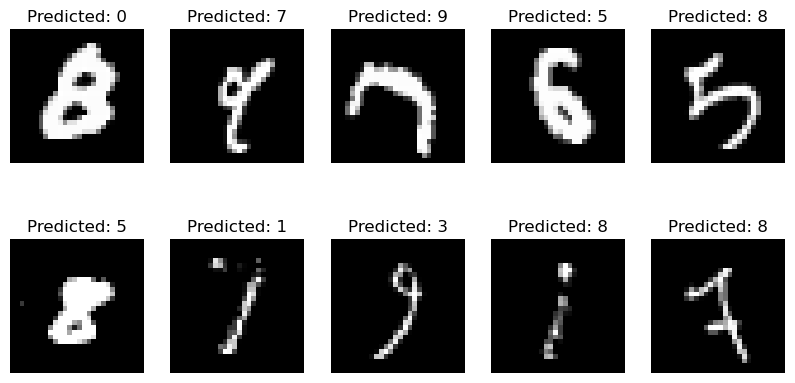

In [76]:
# Get the confidence of the misclassified images
confidence = np.max(A2, axis=0)[predictions != labels]
sorted_indices = np.argsort(confidence)

# Visualize the misclassified images ordered by confidence
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()
    
for i in range(10):
    axes[i].imshow(misclassified_images[sorted_indices[i]].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Predicted: {misclassified_labels[sorted_indices[i]]}")
    axes[i].axis('off')
    
plt.show()

In [ ]:
# Find the most uncertain images

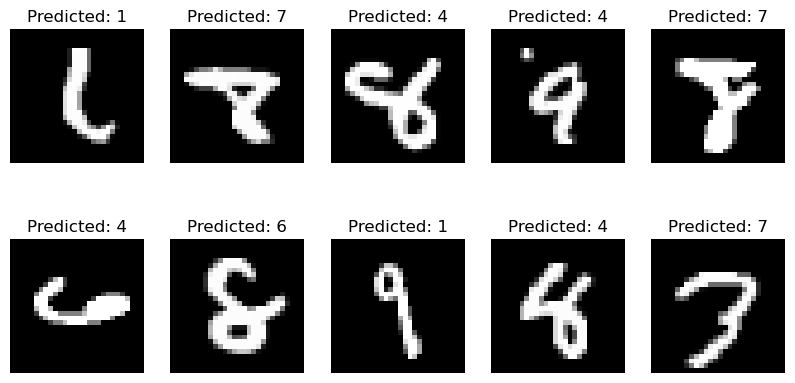

In [77]:
# Get the uncertainty of the misclassified images
uncertainty = 1 - np.max(A2, axis=0)[predictions != labels]
sorted_indices = np.argsort(uncertainty)

# Visualize the misclassified images ordered by uncertainty
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.ravel()

# Visualize the most uncertain images
for i in range(10):
    axes[i].imshow(misclassified_images[sorted_indices[i]].reshape(28, 28), cmap='gray')
    axes[i].set_title(f"Predicted: {misclassified_labels[sorted_indices[i]]}")
    axes[i].axis('off')

plt.show()

In [ ]:
# Find the numbers that are most difficult to classify
